# spectral-watermark: Interactive Showcase & Quickstart

An offline, reproducible tour of full-color embedding, blind recovery, image attacks, and the command-line interface. Everything is generated in memory; no sample-image downloads are needed.

## 1. Introduction & How It Works

A blind watermark can be recovered without the original cover. The default pipeline repeats a short encoded message in **64 × 64 spatial tiles**. Each tile's 2D FFT carries bits as pairwise magnitude changes in a mid-frequency ring; pilot peaks help calibrate display scaling. A **`0x5AA5` sync preamble** and Reed–Solomon error correction frame the UTF-8 payload. RGB and RGBA images are processed through floating-point **ITU-R BT.601 luminance (Y)**; equal channel adjustments preserve chroma, and alpha is retained.

In [1]:
import io
import math
import subprocess
import sys
import tempfile
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Circle
from PIL import Image
from scipy.ndimage import gaussian_filter

from spectral_watermark import (
    BitCodec,
    PilotCalibrator,
    SpectralEngine,
    WatermarkPipeline,
    __version__,
    trim_solid_borders,
)

print(f"spectral-watermark {__version__}")
print("Core imports verified:", WatermarkPipeline.__name__, SpectralEngine.__name__, BitCodec.__name__)
print(f"Sync preamble: 0x{BitCodec.SYNC_MARKER.hex().upper()}")
print("Pilot calibrator:", PilotCalibrator.__name__)


spectral-watermark 0.1.0
Core imports verified: WatermarkPipeline SpectralEngine BitCodec
Sync preamble: 0x5AA5
Pilot calibrator: PilotCalibrator


## 2. Full-Color RGB Embedding & Spectral Visualization

Create a vibrant gradient with deterministic, softly filtered spatial texture. Embed `SPECTRAL_GUIDE_2026`, then compare the exact RGB PSNR and inspect a 64 × 64 tile's luminance-residual spectrum.

Encoded frame: 240 bits
Exact RGB PSNR: 32.67 dB
Maximum per-pixel difference between R/G/B changes: 0 (0 = no chroma tint)


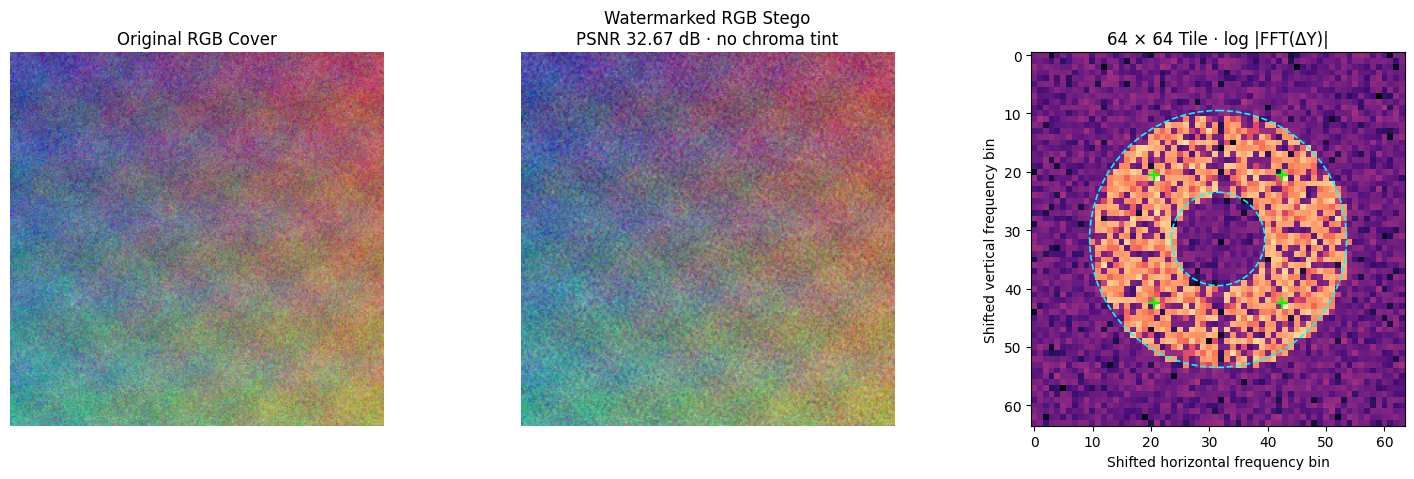

In [2]:
rng = np.random.default_rng(2026)
height = width = 256
yy, xx = np.mgrid[0:height, 0:width]
x = xx / (width - 1)
y = yy / (height - 1)
grain = gaussian_filter(
    rng.normal(0.0, 1.0, size=(height, width, 3)),
    sigma=(1.1, 1.1, 0.0),
)
cover = np.stack(
    (
        68 + 112 * x + 10 * np.sin(2 * np.pi * (x + y) * 5),
        72 + 94 * y + 9 * np.cos(2 * np.pi * (x - y) * 4),
        92 + 68 * (1 - x) + 12 * np.sin(2 * np.pi * y * 5),
    ),
    axis=-1,
) + 22 * grain + rng.normal(0.0, 16.0, size=(height, width, 3))
cover = np.clip(cover, 24, 231).astype(np.uint8)

payload = "SPECTRAL_GUIDE_2026"
pipeline = WatermarkPipeline()
stego, bit_length = pipeline.embed_image(cover, payload)
rgb_difference = cover.astype(np.float64) - stego.astype(np.float64)
mse = float(np.mean(rgb_difference**2))
rgb_psnr = math.inf if mse == 0 else 20 * math.log10(255 / math.sqrt(mse))
channel_delta = stego.astype(np.int16) - cover.astype(np.int16)
max_channel_delta_spread = int(np.ptp(channel_delta, axis=2).max())
print(f"Encoded frame: {bit_length} bits")
print(f"Exact RGB PSNR: {rgb_psnr:.2f} dB")
print(f"Maximum per-pixel difference between R/G/B changes: {max_channel_delta_spread} (0 = no chroma tint)")
assert stego.shape == cover.shape and max_channel_delta_spread == 0

weights = np.array([0.299, 0.587, 0.114])
cover_y = cover.astype(np.float64) @ weights
stego_y = stego.astype(np.float64) @ weights
delta_y_tile = (stego_y - cover_y)[:64, :64]
spectrum = np.fft.fftshift(np.fft.fft2(delta_y_tile))
spectrum_view = np.log1p(np.abs(spectrum))
fig, axes = plt.subplots(1, 3, figsize=(15, 4.7))
axes[0].imshow(cover)
axes[0].set_title("Original RGB Cover")
axes[1].imshow(stego)
axes[1].set_title(f"Watermarked RGB Stego\nPSNR {rgb_psnr:.2f} dB · no chroma tint")
axes[2].imshow(spectrum_view, cmap="magma", origin="upper")
axes[2].set_title("64 × 64 Tile · log |FFT(ΔY)|")
axes[2].set_xlabel("Shifted horizontal frequency bin")
axes[2].set_ylabel("Shifted vertical frequency bin")
center = (31.5, 31.5)
for radius, style in ((8, "--"), (22, "--")):
    axes[2].add_patch(Circle(center, radius, fill=False, color="cyan", linestyle=style, linewidth=1.2))
pilot_offset = pipeline.calibrator.coord_offset
pilot_rows = (31.5 - pilot_offset, 31.5 + pilot_offset)
pilot_cols = (31.5 - pilot_offset, 31.5 + pilot_offset)
for row in pilot_rows:
    for col in pilot_cols:
        axes[2].scatter(col, row, marker="+", s=70, linewidths=1.6, color="lime")
for axis in axes[:2]:
    axis.axis("off")
fig.tight_layout()
plt.show()


## 3. Blind Extraction Under Real-World Distortions

Each attack is applied in memory. Extraction uses the public `extract_from_crop(..., expected_bit_len=..., search_stride=2)` API; the screenshot case leaves scale selection automatic so border trimming and pilot calibration can do their work.

Unaligned crop | 50% removed: 'SPECTRAL_GUIDE_2026' | 308.6 ms
JPEG | quality=75, 4:2:0: 'SPECTRAL_GUIDE_2026' | 8.2 ms
Scaled screenshot | auto 1.24x: 'SPECTRAL_GUIDE_2026' | 17.6 ms
RGBA | alpha preserved: 'SPECTRAL_GUIDE_2026' | 9.0 ms
RGBA alpha exactly preserved: True


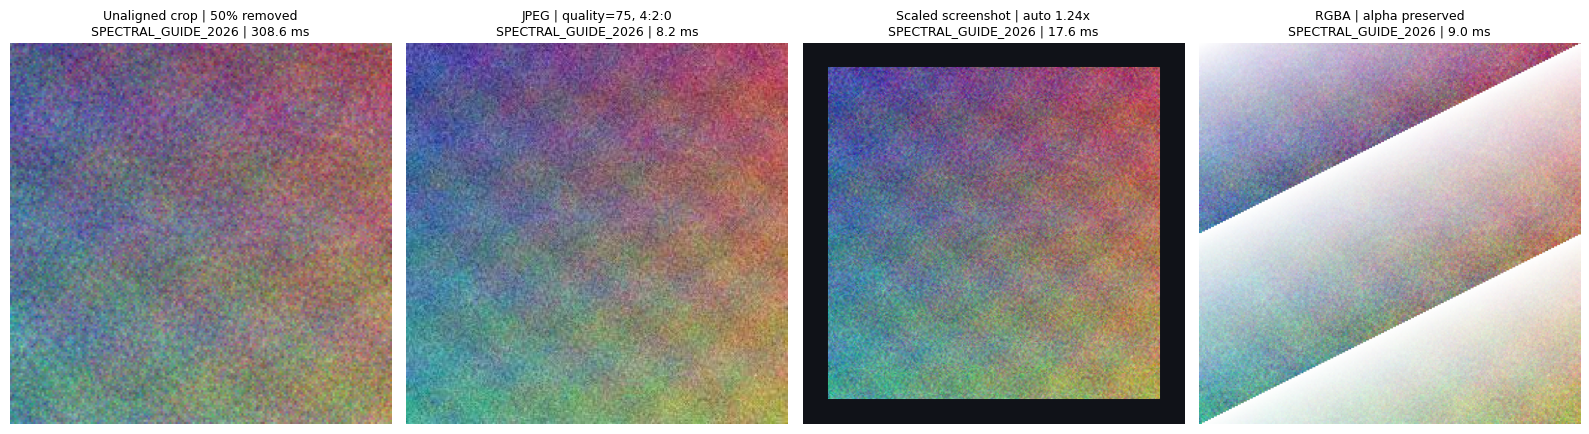

In [3]:
crop = stego[29:209, 37:217]  # 180 × 180: prime offsets, about half the area removed
jpeg_buffer = io.BytesIO()
Image.fromarray(stego).save(jpeg_buffer, format="JPEG", quality=75, subsampling=2)
jpeg_buffer.seek(0)
with Image.open(jpeg_buffer) as compressed:
    jpeg_attack = np.asarray(compressed.convert("RGB")).copy()

scaled = Image.fromarray(stego).resize((320, 320), Image.Resampling.BICUBIC)
scaled_pixels = np.asarray(scaled)
screenshot = np.full((368, 368, 3), (16, 18, 24), dtype=np.uint8)
screenshot[24:-24, 24:-24] = scaled_pixels
trimmed_screenshot = trim_solid_borders(screenshot)
detected_scale = pipeline.calibrator.estimate_scale(trimmed_screenshot)

alpha = ((xx + 2 * yy) % 256).astype(np.uint8)
rgba_cover = np.dstack((cover, alpha))
rgba_stego, rgba_bit_length = pipeline.embed_image(rgba_cover, payload)
alpha_preserved = np.array_equal(rgba_cover[..., 3], rgba_stego[..., 3])
assert alpha_preserved

attacks = [
("Unaligned crop | 50% removed", crop),
("JPEG | quality=75, 4:2:0", jpeg_attack),
(f"Scaled screenshot | auto {detected_scale:.2f}x", screenshot),
("RGBA | alpha preserved", rgba_stego),
]
results = []
for label, attacked in attacks:
    started = time.perf_counter()
    recovered = pipeline.extract_from_crop(
        attacked,
        expected_bit_len=rgba_bit_length if attacked.ndim == 3 and attacked.shape[2] == 4 else bit_length,
        search_stride=2,
    )
    elapsed_ms = (time.perf_counter() - started) * 1000
    results.append((label, attacked, recovered, elapsed_ms))
    print(f"{label}: {recovered!r} | {elapsed_ms:.1f} ms")
    assert recovered == payload
print(f"RGBA alpha exactly preserved: {alpha_preserved}")

fig, axes = plt.subplots(1, 4, figsize=(16, 4.6))
for axis, (label, attacked, recovered, elapsed_ms) in zip(axes, results):
    axis.imshow(attacked)
    axis.set_title(f"{label}\n{recovered} | {elapsed_ms:.1f} ms", fontsize=9)
    axis.axis("off")
fig.tight_layout()
plt.show()


## 4. CLI Quickstart: `embed`, `extract`, `benchmark`

The same workflows are available from the `spectral-watermark` command. This cell invokes the installed package with the notebook's Python, keeps all PNGs in a temporary directory, and prints the benchmark's formatted attack table.

In [4]:
def run_cli(*arguments: str) -> subprocess.CompletedProcess[str]:
    result = subprocess.run(
        [sys.executable, "-m", "spectral_watermark.cli", *arguments],
        check=False,
        capture_output=True,
        text=True,
    )
    if result.returncode != 0:
        raise RuntimeError(f"CLI failed ({result.returncode}):\n{result.stderr}\n{result.stdout}")
    return result

with tempfile.TemporaryDirectory(prefix="spectral-watermark-") as temp_dir:
    temp_path = Path(temp_dir)
    cover_path = temp_path / "cover.png"
    stego_path = temp_path / "stego.png"
    Image.fromarray(cover).save(cover_path)

    embedded = run_cli(
        "embed", "--input", str(cover_path), "--payload", payload, "--output", str(stego_path)
    )
    print("$ spectral-watermark embed --input cover.png --payload ... --output stego.png")
    print(embedded.stdout.strip())

    extracted = run_cli(
        "extract", "--input", str(stego_path), "--bit-len", str(bit_length), "--quiet"
    )
    print("\n$ spectral-watermark extract --input stego.png --bit-len ... --quiet")
    print("Recovered:", extracted.stdout.strip())
    assert extracted.stdout.strip() == payload

    benchmark = run_cli("benchmark", "--input", str(cover_path), "--payload", "DEMO_2026", "--seed", "42")
    print("\n$ spectral-watermark benchmark --input cover.png --payload DEMO_2026 --seed 42")
    print(benchmark.stdout.strip())
    assert "Attack Name" in benchmark.stdout and "Exact Match" in benchmark.stdout

print("Temporary image files cleaned up.")


$ spectral-watermark embed --input cover.png --payload ... --output stego.png
Watermarked image saved to: C:\Users\Ben\AppData\Local\Temp\spectral-watermark-0dit50w2\stego.png
Dimensions: 256x256
Payload bit length: 240
Stego PSNR: 32.67 dB
Elapsed: 44.87 ms



$ spectral-watermark extract --input stego.png --bit-len ... --quiet
Recovered: SPECTRAL_GUIDE_2026



$ spectral-watermark benchmark --input cover.png --payload DEMO_2026 --seed 42
Baseline embedding PSNR: 34.19 dB
Attack Name             | Attack PSNR / Param  | Recovered | Exact Match | Time (ms)
------------------------+----------------------+-----------+-------------+----------
Baseline (No Attack)    | 34.19 dB             | Yes       | PASS        | 11.71    
Center / Unaligned Crop | 50% area             | Yes       | PASS        | 228.19   
JPEG Compression        | quality=75; 24.07 dB | Yes       | PASS        | 9.53     
JPEG Compression        | quality=50; 23.76 dB | No        | FAIL        | 2923.84  
Gaussian Blur           | radius=0.8; 26.35 dB | Yes       | PASS        | 9.27     
Gaussian Noise          | sigma=3.0; 38.40 dB  | Yes       | PASS        | 9.67
Temporary image files cleaned up.


## 5. Best Practices & Reference

| Topic | Practical guidance |
|---|---|
| Minimum image size | The CLI requires at least **64 × 64 px** so a complete tile can be searched. |
| Payload | About **29 UTF-8 bytes per tile** (up to roughly **320 encoded bits**); multibyte characters count by bytes. |
| Output format | Prefer **PNG or another lossless format** for embedding and archival. JPEG is useful for testing robustness but each lossy save can reduce recovery margin. |
| `--scale FACTOR` | Repeat for known screenshot zoom values, e.g. `--scale 1.25 --scale 1.5`. Automatic pilot calibration is attempted too. |
| `--multi-scale` | Add the built-in scale sweep when zoom is unknown: `1.0`, `1.25`, `1.5`, `0.8`, and `0.75`. |
| `--stride N` | Set the sliding-search pixel step (default `2`); a smaller value checks more offsets and takes longer. |

The Python API returns `(stego_array, bit_length)` from `embed_image`; use that length with `extract_from_crop` for a faster known-payload scan. The CLI's `extract` can instead search candidate UTF-8 payload lengths when `--bit-len` is omitted.